In [ ]:
!pip install boto3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 24.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [boto3]


In [ ]:
import boto3, cv2, numpy as np, os
from dotenv import load_dotenv
from PIL import Image
from google.colab.patches import cv2_imshow

In [ ]:
%%writefile .env
aws_bucket=amzn-s3-jma
aws_region=us-east-1
aws_access_key_id=PEGA_AQUI_TU_ACCESS_KEY_ID
aws_secret_access_key=PEGA_AQUI_TU_SECRET_ACCESS_KEY
aws_session_token=PEGA_AQUI_TU_SESSION_TOKEN

Overwriting .env


In [ ]:
load_dotenv(override=True)

aws_access_key_id = os.environ.get('aws_access_key_id')
aws_secret_access_key = os.environ.get('aws_secret_access_key')
aws_session_token = os.environ.get('aws_session_token')
aws_bucket = os.environ.get('aws_bucket')
aws_region = os.environ.get('aws_region')

In [ ]:
session = boto3.Session(
        aws_access_key_id = aws_access_key_id,
        aws_secret_access_key = aws_secret_access_key,
        aws_session_token = aws_session_token,
        region_name = aws_region)
s3 = session.resource('s3')
rekognition = session.client('rekognition')

In [ ]:
file = 'caras.jpg'
key = 'caras.jpg'
try:
  s3.Object(aws_bucket, key).upload_file(file)
except Exception as e:
  print(e)

In [ ]:
try:
  response = rekognition.detect_faces(Image={'S3Object': {'Bucket': aws_bucket, 'Name': key}}, Attributes=['ALL'])
except Exception as e:
  print(e)

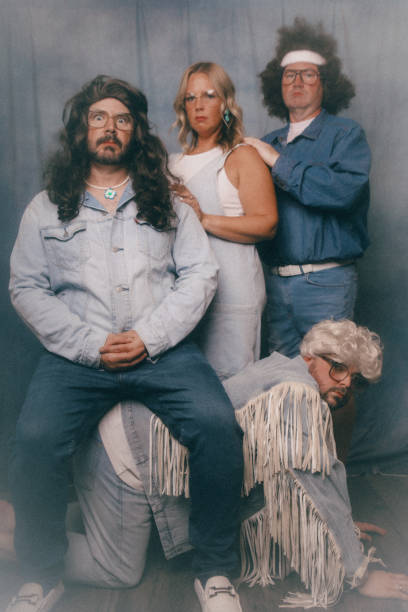

True

In [ ]:
img = Image.open(file)
img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGRA)

height, width, _ = img_cv2.shape

cv2_imshow(img_cv2)

#for faceDetail in response['FaceDetails']:
 # box = faceDetail['BoundingBox']
  #x = int(width * box['Left'])
  #y = int(height * box['Top'])
  #w = int(width * box['Width'])
  #h = int(height * box['Height'])
  #roi = img_cv2[y:y+h, x:x+w]
  #roi = cv2.GaussianBlur(roi, (83, 83), 30)
  #img_cv2[y:y+roi.shape[0], x:x+roi.shape[1]] = roi
#cv2.imwrite('faces_blur.jpg', img_cv2)

In [ ]:
response

{'FaceDetails': [{'BoundingBox': {'Width': 0.12375431507825851,
    'Height': 0.10570944845676422,
    'Left': 0.20757749676704407,
    'Top': 0.1580129861831665},
   'AgeRange': {'Low': 38, 'High': 46},
   'Smile': {'Value': False, 'Confidence': 98.27950286865234},
   'Eyeglasses': {'Value': True, 'Confidence': 93.62551879882812},
   'Sunglasses': {'Value': False, 'Confidence': 99.89126586914062},
   'Gender': {'Value': 'Male', 'Confidence': 96.2785415649414},
   'Beard': {'Value': True, 'Confidence': 98.9549789428711},
   'Mustache': {'Value': True, 'Confidence': 82.85142517089844},
   'EyesOpen': {'Value': True, 'Confidence': 99.89968872070312},
   'MouthOpen': {'Value': False, 'Confidence': 92.6529312133789},
   'Emotions': [{'Type': 'SURPRISED', 'Confidence': 73.00970458984375},
    {'Type': 'FEAR', 'Confidence': 41.20680236816406},
    {'Type': 'CONFUSED', 'Confidence': 5.5592851638793945},
    {'Type': 'DISGUSTED', 'Confidence': 0.29144287109375},
    {'Type': 'ANGRY', 'Confiden

In [ ]:
for faceDetail in response['FaceDetails']:
  box = faceDetail['BoundingBox']
  x = int(width * box['Left'])
  y = int(height * box['Top'])
  w = int(width * box['Width'])
  h = int(height * box['Height'])
  roi = img_cv2[y:y+h, x:x+w]
  roi = cv2.GaussianBlur(roi, (83, 83), 30)
  img_cv2[y:y+roi.shape[0], x:x+roi.shape[1]] = roi
cv2.imwrite('faces_blur.jpg', img_cv2)

True

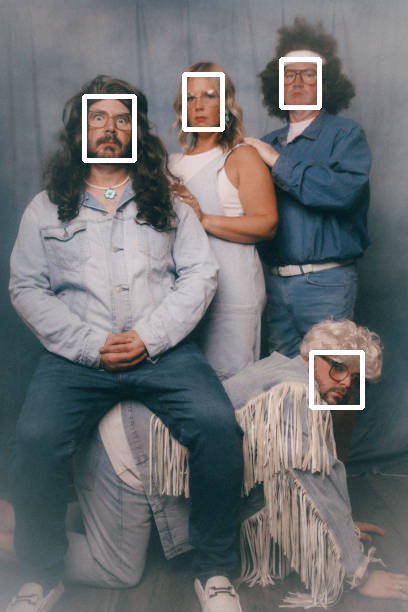

In [23]:
img = Image.open(file)
img_cv2 = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGRA)

height, width, _ = img_cv2.shape

for faceDetail in response['FaceDetails']:
  box = faceDetail['BoundingBox']
  x = int(width * box['Left'])
  y = int(height * box['Top'])
  w = int(width * box['Width'])
  h = int(height * box['Height'])
  cv2.rectangle(img_cv2, (x, y), (x + w, y + h), (0, 255, 0), 3)
cv2.imwrite('faces_rect.jpg', img_cv2)
cv2_imshow(img_cv2)

# Ejercicios

1. Desarrolla un script que detecte personas en una fotografía y genere un informe con los resultados que puedas extraer. En este caso, se obtiene más información que en la práctica anterior. [que de algún dato extra, un pequeño informe es suficiente]

2. Modifica el código proporcionado para que, utilizando Amazon Rekognition y OpenCV, se aplique un efecto de desenfoque (blur) a toda la imagen, manteniendo los rostros detectados nítidos y sin desenfocar. La idea es utilizar cv2.GaussianBlur() para desenfocar la imagen completa y, después, copiar sobre ella las regiones faciales de la imagen original utilizando las coordenadas que devuelve Rekognition. [Hay que desenfocar la imagen entera con gausianblur, y una vez desenfocada toda la imagen pintemos las imágenes enfocadas]

3. Modifica el código proporcionado para que, utilizando Amazon Rekognition y OpenCV, se detecten y recorten todos los rostros de una fotografía y se genere un collage que contenga únicamente los rostros detectados.
Requisitos:
    Detectar los rostros de la imagen mediante Amazon Rekognition.
    Recortar cada rostro utilizando las coordenadas devueltas por el servicio.
    Redimensionar los recortes para que tengan unas dimensiones uniformes.
    Organizar los rostros en una cuadrícula y generar una única imagen con todos ellos.
    Mostrar y guardar el collage resultante.
Ampliación: modifica el número de filas y columnas del collage y comprueba el resultado con fotografías que contengan diferentes cantidades de rostros. (redimensionamos a la más grande para que todas sean iguales. Se va a desfigurar un poco pero no importa. Imagina que hacemos 5 caras, buscamos el cuadrado mas cercano mayor o igual, por enemplo para 5 caras hacemos un collage de 3x3)

In [29]:
# ── Ejercicio 1 · Paso 1: analizar la foto con Rekognition ──────────────────────
# Hacemos dos análisis de la misma foto:
#   · detect_faces  → cada cara: edad, género aparente, emociones, gafas, barba...
#   · detect_labels → la escena: personas (cuerpos), ropa, objetos, colores y calidad
file_ej1 = 'caras_ej1.jpg'
key_ej1 = 'caras_ej1.jpg'

s3.Object(aws_bucket, key_ej1).upload_file(file_ej1)
foto_s3 = {'S3Object': {'Bucket': aws_bucket, 'Name': key_ej1}}

resp_caras = rekognition.detect_faces(Image=foto_s3, Attributes=['ALL'])
resp_etiquetas = rekognition.detect_labels(Image=foto_s3, MaxLabels=100, MinConfidence=50,
                                           Features=['GENERAL_LABELS', 'IMAGE_PROPERTIES'])

print(f"Rekognition ha encontrado {len(resp_caras['FaceDetails'])} caras "
      f"y {len(resp_etiquetas['Labels'])} etiquetas en la escena.")


Rekognition ha encontrado 9 caras y 100 etiquetas en la escena.


In [30]:
# ── Ejercicio 1 · Paso 2: entender quién es quién ──────────────────────────────
# Rekognition devuelve las caras por un lado y los objetos por otro. Aquí los cruzamos:
#   1. ¿Cada cara es de una persona de la escena? (tiene un cuerpo o ropa justo debajo)
#   2. ¿Qué ropa lleva cada persona?
#   3. Datos del grupo para poder comparar (quién es la más joven, qué rasgo es raro...)
from collections import Counter

caras = sorted(resp_caras['FaceDetails'], key=lambda c: c['BoundingBox']['Left'])  # de izquierda a derecha
etiquetas = resp_etiquetas['Labels']

# Traducciones propias (Amazon Translate no está permitido en el laboratorio)
PRENDAS = {'Coat': 'una chaqueta', 'Jacket': 'una chaqueta', 'Blazer': 'una americana',
           'Overcoat': 'un abrigo', 'Shirt': 'una camisa', 'T-Shirt': 'una camiseta',
           'Sweater': 'un jersey', 'Hoodie': 'una sudadera', 'Vest': 'un chaleco', 'Suit': 'un traje',
           'Dress': 'un vestido', 'Skirt': 'una falda', 'Jeans': 'unos vaqueros',
           'Pants': 'unos pantalones', 'Shorts': 'unos pantalones cortos'}
ACCESORIOS = {'Glasses': 'unas gafas', 'Sunglasses': 'unas gafas de sol', 'Hat': 'un sombrero',
              'Cap': 'una gorra', 'Belt': 'un cinturón', 'Tie': 'una corbata', 'Scarf': 'una bufanda',
              'Handbag': 'un bolso', 'Backpack': 'una mochila', 'Necklace': 'un collar',
              'Wristwatch': 'un reloj', 'Earring': 'unos pendientes', 'Glove': 'unos guantes'}
COLORES = {'black': 'negros', 'white': 'blancos', 'grey': 'grises', 'gray': 'grises', 'red': 'rojos',
           'orange': 'anaranjados', 'yellow': 'amarillos', 'green': 'verdes', 'blue': 'azules',
           'purple': 'morados', 'pink': 'rosados', 'brown': 'marrones'}
ESCENA = {'Indoors': 'interior', 'Outdoors': 'exterior', 'Room': 'habitación', 'Living Room': 'salón',
          'Restaurant': 'restaurante', 'Cafe': 'cafetería', 'Pub': 'bar', 'Bar Counter': 'barra de bar',
          'Furniture': 'muebles', 'Chair': 'silla', 'Table': 'mesa', 'Couch': 'sofá', 'Lamp': 'lámpara',
          'Art': 'arte', 'Painting': 'cuadro', 'Portrait': 'retrato', 'Photography': 'fotografía',
          'Sculpture': 'escultura', 'Statue': 'estatua', 'Pottery': 'cerámica', 'Food': 'comida',
          'Dessert': 'postre', 'Ice Cream': 'helado', 'Cream': 'nata', 'Plant': 'planta', 'Flower': 'flor',
          'Tree': 'árbol', 'Weapon': 'arma', 'Mace Club': 'maza', 'Sword': 'espada', 'Stick': 'palo',
          'Theater': 'teatro', 'Party': 'fiesta', 'House': 'casa', 'Staircase': 'escalera',
          'Building': 'edificio', 'City': 'ciudad', 'Street': 'calle', 'Nature': 'naturaleza',
          'Sky': 'cielo', 'Beach': 'playa', 'Sea': 'mar', 'Water': 'agua', 'Mountain': 'montaña',
          'Car': 'coche', 'Dog': 'perro', 'Cat': 'gato', 'Animal': 'animal', 'Book': 'libro',
          'Phone': 'teléfono', 'Computer': 'ordenador', 'Laptop': 'portátil', 'Cup': 'taza',
          'Bottle': 'botella', 'Window': 'ventana', 'Door': 'puerta', 'Microphone': 'micrófono',
          'Guitar': 'guitarra', 'Musical Instrument': 'instrumento musical', 'Cross': 'cruz',
          'Altar': 'altar', 'Church': 'iglesia', 'Cave': 'cueva', 'Throne': 'trono', 'Crowd': 'multitud'}

# --- Utilidades de geometría (Rekognition da las cajas en proporción 0-1 de la foto) ---
def caja(b):
    return b['Left'], b['Top'], b['Left'] + b['Width'], b['Top'] + b['Height']

def centro(b):
    x1, y1, x2, y2 = caja(b)
    return (x1 + x2) / 2, (y1 + y2) / 2

def dentro(punto, b):
    x1, y1, x2, y2 = caja(b)
    return x1 <= punto[0] <= x2 and y1 <= punto[1] <= y2

def mediana(valores):
    valores = sorted(valores)
    return valores[len(valores) // 2] if valores else 0

def de_personas(etiqueta):
    return any(c['Name'] == 'Person Description' for c in etiqueta.get('Categories', []))

def instancias(filtro):
    """Objetos con recuadro de todas las etiquetas que cumplen el filtro."""
    return [dict(i, Nombre=l['Name']) for l in etiquetas if filtro(l) for i in l.get('Instances', [])]

cuerpos = [i for i in instancias(lambda l: l['Name'] == 'Person') if i['Confidence'] >= 80]
ropa = instancias(lambda l: l['Name'] in PRENDAS or l['Name'] in ACCESORIOS)
objetos = instancias(lambda l: not de_personas(l) and l['Name'] not in PRENDAS and l['Name'] not in ACCESORIOS)

# --- 1. ¿Qué caras son personas de la escena? ---
fichas = [{'cara': c, 'tipo': None, 'cuerpo': None, 'ropa': [], 'ropa_debajo': []} for c in caras]
altura_tipica = mediana([c['BoundingBox']['Height'] for c in caras])

# a) Caras diminutas comparadas con el resto: figuras del fondo (cuadros, fotos de la pared...)
for f in fichas:
    if f['cara']['BoundingBox']['Height'] < 0.25 * altura_tipica:
        f['tipo'] = 'fondo'

# b) Emparejar caras y cuerpos: la cara debe estar en la parte de arriba del cuerpo.
#    Si en un cuerpo caben dos caras, se queda la que está más arriba (la otra será otra cosa).
parejas = []
for i, f in enumerate(fichas):
    if f['tipo']:
        continue
    cx, cy = centro(f['cara']['BoundingBox'])
    for n, cuerpo in enumerate(cuerpos):
        x1, y1, x2, y2 = caja(cuerpo['BoundingBox'])
        if x1 <= cx <= x2 and y1 <= cy <= y1 + 0.4 * (y2 - y1):
            parejas.append(((cy - y1) / (y2 - y1), i, n))
cuerpos_usados = set()
for _, i, n in sorted(parejas):
    if fichas[i]['cuerpo'] is None and n not in cuerpos_usados:
        fichas[i]['cuerpo'], fichas[i]['tipo'] = cuerpos[n], 'persona'
        cuerpos_usados.add(n)

# c) Caras sin cuerpo: si justo debajo hay una prenda, también es una persona
#    (Rekognition no siempre marca el cuerpo, por ejemplo si está sentada o tapada)
for f in fichas:
    if f['tipo']:
        continue
    cx, cy = centro(f['cara']['BoundingBox'])
    y_barbilla, alto = caja(f['cara']['BoundingBox'])[3], f['cara']['BoundingBox']['Height']
    f['ropa_debajo'] = [p for p in ropa if p['Nombre'] in PRENDAS
                        and caja(p['BoundingBox'])[0] <= cx <= caja(p['BoundingBox'])[2]
                        and cy <= p['BoundingBox']['Top'] <= y_barbilla + alto]
    sin_datos = not cuerpos and not ropa      # detect_labels no ha visto ni cuerpos ni ropa: no podemos comprobarlo
    f['tipo'] = 'persona' if f['ropa_debajo'] or sin_datos else 'sin_cuerpo'

personas = [f for f in fichas if f['tipo'] == 'persona']
otras_caras = [f for f in fichas if f['tipo'] != 'persona']
for n, f in enumerate(personas, 1):
    f['id'] = str(n)
for letra, f in zip('ABCDEFGHIJKLMNOPQRSTUVWXYZ', otras_caras):
    f['id'] = letra

# --- 2. Repartir la ropa: cada prenda es de la persona cuyo cuerpo la contiene ---
#        (si encaja en dos, de la que tiene la cara más cerca en horizontal)
for prenda in ropa:
    punto = centro(prenda['BoundingBox'])
    candidatas = [f for f in personas if prenda in f['ropa_debajo']
                  or (f['cuerpo'] and dentro(punto, f['cuerpo']['BoundingBox']))]
    if candidatas:
        duena = min(candidatas, key=lambda f: abs(centro(f['cara']['BoundingBox'])[0] - punto[0]))
        duena['ropa'].append(prenda)

# --- 3. Datos del grupo (solo personas de la escena) ---
n_personas = len(personas)
nitidez_tipica = mediana([f['cara']['Quality']['Sharpness'] for f in personas])

def edad_media(f):
    return (f['cara']['AgeRange']['Low'] + f['cara']['AgeRange']['High']) / 2

def emocion(f):
    return max(f['cara']['Emotions'], key=lambda e: e['Confidence'])

def cuantas(condicion):
    return sum(1 for f in personas if condicion(f))

def rareza(condicion):
    """1 si solo una persona cumple la condición; casi 0 si la cumple todo el grupo."""
    return 1 - cuantas(condicion) / n_personas + 1 / n_personas

for f in personas:
    print(f"Persona {f['id']}: {'cuerpo detectado' if f['cuerpo'] else 'sin cuerpo, pero con ropa debajo'}"
          f" · ropa: {', '.join(p['Nombre'] for p in f['ropa']) or '-'}")
for f in otras_caras:
    print(f"Cara {f['id']}: no es una persona de la escena ({f['tipo']})")


Persona 1: cuerpo detectado · ropa: Coat, Belt
Persona 2: sin cuerpo, pero con ropa debajo · ropa: Coat
Persona 3: cuerpo detectado · ropa: Glasses
Persona 4: cuerpo detectado · ropa: -
Persona 5: cuerpo detectado · ropa: Jeans
Persona 6: cuerpo detectado · ropa: -
Cara A: no es una persona de la escena (fondo)
Cara B: no es una persona de la escena (fondo)
Cara C: no es una persona de la escena (sin_cuerpo)


In [35]:
# ── Ejercicio 1 · Paso 3: redactar una descripción personalizada ────────────────
# Para cada persona se generan frases candidatas con una puntuación:
#       puntuación = seguridad del modelo × rareza en el grupo × interés del rasgo
# y solo se cuentan las 3 mejores. Así cada descripción destaca lo que diferencia
# a esa persona del resto, en vez de repetir los mismos datos para todo el mundo.
import re

EMOCIONES = {  # artículo, nombre, adjetivo masculino, adjetivo femenino
    'CALM': ('la', 'calma', 'tranquilo', 'tranquila'), 'HAPPY': ('la', 'alegría', 'contento', 'contenta'),
    'SAD': ('la', 'tristeza', 'triste', 'triste'), 'ANGRY': ('el', 'enfado', 'enfadado', 'enfadada'),
    'CONFUSED': ('la', 'confusión', 'confundido', 'confundida'),
    'SURPRISED': ('la', 'sorpresa', 'sorprendido', 'sorprendida'),
    'DISGUSTED': ('el', 'disgusto', 'disgustado', 'disgustada'), 'FEAR': ('el', 'miedo', 'asustado', 'asustada')}

# Rasgos de la cara: frase normal, frase si es la ÚNICA del grupo, frase si es la única que NO lo tiene, interés
RASGOS = {
    'Smile':        ('Sonríe', 'Es la única persona del grupo que sonríe',
                     'Es la única persona del grupo que no sonríe', 1.0),
    'Eyeglasses':   ('Lleva gafas', 'Es la única persona con gafas', 'Es la única persona sin gafas', 0.9),
    'Sunglasses':   ('Lleva gafas de sol', 'Es la única persona con gafas de sol', None, 1.0),
    'Beard':        ('Lleva barba', 'Es la única persona con barba', None, 0.9),
    'Mustache':     ('Lleva bigote', 'Es la única persona con bigote', None, 0.9),
    'MouthOpen':    ('Tiene la boca abierta', 'Es la única persona con la boca abierta', None, 0.7),
    'FaceOccluded': ('Algo le tapa parte de la cara', 'Algo le tapa parte de la cara', None, 0.9)}

POSTURAS = [  # condición sobre la pose de la cabeza (grados), frase, interés
    (lambda p: abs(p['Roll']) > 20, 'Inclina la cabeza hacia un lado', 0.7),
    (lambda p: abs(p['Yaw']) > 30, 'Tiene la cara girada hacia un lado', 0.7),
    (lambda p: p['Pitch'] > 20, 'Mira hacia arriba', 0.5),
    (lambda p: p['Pitch'] < -20, 'Mira hacia abajo', 0.5)]

PALABRAS = {'mujer': ('una', 'mujeres'), 'hombre': ('un', 'hombres'), 'niña': ('una', 'niñas'),
            'niño': ('un', 'niños'), 'chica': ('una', 'chicas'), 'chico': ('un', 'chicos'),
            'persona': ('una', 'personas')}
NUMEROS = {2: 'dos', 3: 'tres', 4: 'cuatro', 5: 'cinco', 6: 'seis', 7: 'siete', 8: 'ocho', 9: 'nueve', 10: 'diez'}

def lista(cosas):
    """['a', 'b', 'c'] → 'a, b y c'"""
    cosas = list(dict.fromkeys(cosas))  # sin repetidos, manteniendo el orden
    return cosas[0] if len(cosas) == 1 else ', '.join(cosas[:-1]) + ' y ' + cosas[-1]

def quien(f):
    """('una mujer joven', 'f'), ('un niño', 'm')... según la edad y el género aparentes."""
    c, edad = f['cara'], edad_media(f)
    if c['Gender']['Confidence'] < 90:
        return 'una persona', 'f'
    fem = c['Gender']['Value'] == 'Female'
    if edad < 13:
        return ('una niña', 'f') if fem else ('un niño', 'm')
    if edad < 18:
        return ('una chica', 'f') if fem else ('un chico', 'm')
    extra = ' joven' if edad < 30 else ' mayor' if edad >= 60 else ''
    return ('una mujer' + extra, 'f') if fem else ('un hombre' + extra, 'm')

def donde(f):
    cx = centro(f['cara']['BoundingBox'])[0]
    lado = 'A la izquierda' if cx < 0.33 else 'A la derecha' if cx > 0.66 else 'En el centro'
    mas_grande = max(g['cara']['BoundingBox']['Height'] for g in personas)
    return lado + (', en primer plano,' if f['cara']['BoundingBox']['Height'] >= 0.8 * mas_grande else '')

def frase_emocion(f, i):
    emos = sorted(f['cara']['Emotions'], key=lambda e: -e['Confidence'])
    e1, e2 = emos[0], emos[1]
    _, nombre, adj_m, adj_f = EMOCIONES[e1['Type']]
    adj = adj_f if quien(f)[1] == 'f' else adj_m
    if e1['Confidence'] < 50:
        return 0.7, f"Su expresión es difícil de leer: el modelo duda entre {nombre} y {EMOCIONES[e2['Type']][1]}"
    misma = lambda g: emocion(g)['Type'] == e1['Type']
    if e1['Confidence'] < 80:
        texto = f"Da la impresión de estar {adj}, aunque el modelo no está del todo seguro ({e1['Confidence']:.0f} %)"
    else:
        texto = [f"Se le ve {adj}", f"Su gesto transmite {nombre}", f"Parece {adj}"][i % 3]
    if cuantas(misma) == 1 and n_personas > 2:
        texto += f", y es la única persona del grupo con gesto de {nombre}"
    return e1['Confidence'] / 100 * rareza(misma), texto

def frase_ropa(f):
    c, prendas, accesorios = f['cara'], [], []
    for p in f['ropa']:
        if p['Nombre'] in PRENDAS:
            colores = p.get('DominantColors') or []
            color = COLORES.get(colores[0]['SimplifiedColor']) if colores else None
            prendas.append(PRENDAS[p['Nombre']] + (f' en tonos {color}' if color else ''))
        elif p['Nombre'] in ('Glasses', 'Sunglasses'):
            if not (c['Eyeglasses']['Value'] or c['Sunglasses']['Value']):   # las gafas no están en su cara
                accesorios.append(ACCESORIOS[p['Nombre']] + ', aunque no puestas')
        else:
            accesorios.append(ACCESORIOS[p['Nombre']])
    partes = (['viste ' + lista(prendas)] if prendas else []) + (['lleva ' + lista(accesorios)] if accesorios else [])
    return ' y '.join(partes).capitalize() if partes else None

def candidatas(f, i):
    """Todas las frases posibles para esta persona: (puntuación, orden en el texto, frase)."""
    c, salida = f['cara'], []
    for atr, (normal, unica_si, unica_no, interes) in RASGOS.items():
        valor, seguridad = c[atr]['Value'], c[atr]['Confidence'] / 100
        igual = lambda g, atr=atr, valor=valor: g['cara'][atr]['Value'] == valor
        es_unica = cuantas(igual) == 1 and n_personas > 2
        if valor:
            salida.append((seguridad * rareza(igual) * interes, 1, unica_si if es_unica else normal))
        elif es_unica and unica_no:
            salida.append((seguridad * interes, 1, unica_no))
    if not c['EyesOpen']['Value']:
        salida.append((c['EyesOpen']['Confidence'] / 100 * rareza(lambda g: not g['cara']['EyesOpen']['Value']),
                       1, 'Tiene los ojos cerrados'))
    if n_personas > 2:
        edades = [edad_media(g) for g in personas]
        if edad_media(f) == min(edades):
            salida.append((0.95, 0, 'Es la persona más joven del grupo'))
        elif edad_media(f) == max(edades):
            salida.append((0.95, 0, 'Es la persona de más edad del grupo'))
    for condicion, frase, interes in POSTURAS:
        if condicion(c['Pose']):
            salida.append((interes * rareza(lambda g, cond=condicion: cond(g['cara']['Pose'])), 3, frase))
    ropa_txt = frase_ropa(f)
    if ropa_txt:
        salida.append((0.7, 2, ropa_txt))
    puntos, texto = frase_emocion(f, i)
    salida.append((puntos, 4, texto))
    return salida

def narrar(f, i):
    persona, _ = quien(f)
    r = f['cara']['AgeRange']
    verbo = ['aparece', 'encontramos a', 'vemos a'][i % 3]
    texto = f"{donde(f)} {verbo} {persona} de entre {r['Low']} y {r['High']} años."
    todas = sorted(candidatas(f, i), key=lambda x: -x[0])
    elegidas = [x for x in todas[:3] if x[0] >= 0.3]
    if len(elegidas) < 3:  # si queda hueco, terminamos contando su gesto
        elegidas += [x for x in todas if x[1] == 4 and x not in elegidas]
    frases = [x[2] for x in sorted(elegidas, key=lambda x: x[1])]   # orden natural: edad, cara, ropa...
    if 'Lleva barba' in frases and 'Lleva bigote' in frases:
        frases = [x for x in frases if x != 'Lleva bigote']
        frases[frases.index('Lleva barba')] = 'Lleva barba y bigote'
    texto += ''.join(f' {x}.' for x in frases)
    if f['cuerpo'] is None:
        texto += (' <span class="nota">Rekognition no marcó su cuerpo; el script sabe que es una persona '
                  'por la ropa que tiene justo debajo de la cara.</span>')
    return texto

def narrar_otra(f):
    c, r = f['cara'], f['cara']['AgeRange']
    cx, cy = centro(c['BoundingBox'])
    lado = 'a la izquierda' if cx < 0.33 else 'a la derecha' if cx > 0.66 else 'en el centro'
    if f['tipo'] == 'fondo':
        tam = 100 * c['BoundingBox']['Height'] / altura_tipica
        texto = (f"Cara diminuta al fondo, {lado} (apenas un {tam:.0f} % del tamaño de las demás). "
                 "Seguramente es una figura del fondo (un cuadro, una foto...) o un falso positivo, "
                 "no alguien de la escena.")
    else:
        texto = ("No tiene cuerpo ni ropa debajo, así que seguramente no es una persona real "
                 "(una escultura, un reflejo, un cartel...).")
    encima = [o for o in objetos if dentro((cx, cy), o['BoundingBox'])]
    if encima:
        texto += ' En ese mismo punto Rekognition detecta: ' + lista(
            [f"{ESCENA.get(o['Nombre'], o['Nombre']).lower()} ({o['Confidence']:.0f} %)" for o in encima]) + '.'
    return texto + (f" Aun así, el modelo le calcula entre {r['Low']} y {r['High']} años: "
                    "analiza cualquier cosa con forma de cara.")

def resumen_grupo():
    if not personas:
        return 'Rekognition no ha encontrado a ninguna persona en la escena.'
    tipos = Counter(quien(f)[0].split()[1] for f in personas)   # 'mujer', 'hombre', 'niña'...
    grupos = [f"{PALABRAS[p][0]} {p}" if k == 1 else f"{NUMEROS.get(k, k)} {PALABRAS[p][1]}"
              for p, k in tipos.most_common()]
    lo = min(f['cara']['AgeRange']['Low'] for f in personas)
    hi = max(f['cara']['AgeRange']['High'] for f in personas)
    media = sum(edad_media(f) for f in personas) / n_personas
    sonrien = cuantas(lambda f: f['cara']['Smile']['Value'])
    sonrisas = ('Nadie sonríe' if sonrien == 0 else 'Todo el mundo sonríe' if sonrien == n_personas
                else f'Sonríen {sonrien} de {n_personas}')
    tipo_emo, veces = Counter(emocion(f)['Type'] for f in personas).most_common(1)[0]
    articulo, nombre_emo = EMOCIONES[tipo_emo][:2]
    if n_personas == 1:
        texto = (f"En la foto hay <b>una sola persona</b>: {grupos[0]} (según su apariencia) que aparenta entre "
                 f"{lo} y {hi} años. {'Sonríe' if sonrien else 'No sonríe'}, y su gesto es de {nombre_emo}.")
    else:
        texto = (f"En la foto hay <b>{n_personas} personas</b>: {lista(grupos)} (según su apariencia). "
                 f"Aparentan entre {lo} y {hi} años, con una media de unos {media:.0f}. {sonrisas}, "
                 f"y el gesto que más se repite es {articulo} {nombre_emo} ({veces} de {n_personas}).")
    lugar = {l['Name']: l['Confidence'] for l in etiquetas if l['Name'] in ('Indoors', 'Outdoors')}
    if lugar:
        texto += f" La foto parece tomada en un {ESCENA[max(lugar, key=lugar.get)]}."
    if otras_caras:
        texto += (f" Rekognition ha encontrado <b>{len(caras)} caras</b>, pero "
                  + ("una no es de una persona de la escena" if len(otras_caras) == 1
                     else f"{len(otras_caras)} no son de personas de la escena")
                  + f" ({lista([f['id'] for f in otras_caras])}).")
    return texto

# Vista previa en texto (el informe completo sale en el paso 4)
sin_html = lambda t: re.sub(r'<[^>]+>', '', t)
print(sin_html(resumen_grupo()), '\n')
for i, f in enumerate(personas):
    print(f"Persona {f['id']}: {sin_html(narrar(f, i))}")


En la foto hay 6 personas: tres mujeres, dos hombres y una niña (según su apariencia). Aparentan entre 8 y 69 años, con una media de unos 40. Nadie sonríe, y el gesto que más se repite es la calma (6 de 6). La foto parece tomada en un interior. Rekognition ha encontrado 9 caras, pero 3 no son de personas de la escena (A, B y C). 

Persona 1: A la izquierda aparece una mujer joven de entre 24 y 32 años. Viste una chaqueta en tonos grises y lleva un cinturón. Se le ve tranquila.
Persona 2: En el centro, en primer plano, encontramos a un hombre mayor de entre 63 y 69 años. Es la persona de más edad del grupo. Viste una chaqueta en tonos negros. Su gesto transmite calma. Rekognition no marcó su cuerpo; el script sabe que es una persona por la ropa que tiene justo debajo de la cara.
Persona 3: En el centro vemos a un hombre joven de entre 25 y 33 años. Es la única persona con barba. Lleva unas gafas, aunque no puestas. Parece tranquilo.
Persona 4: En el centro aparece una niña de entre 8 y 


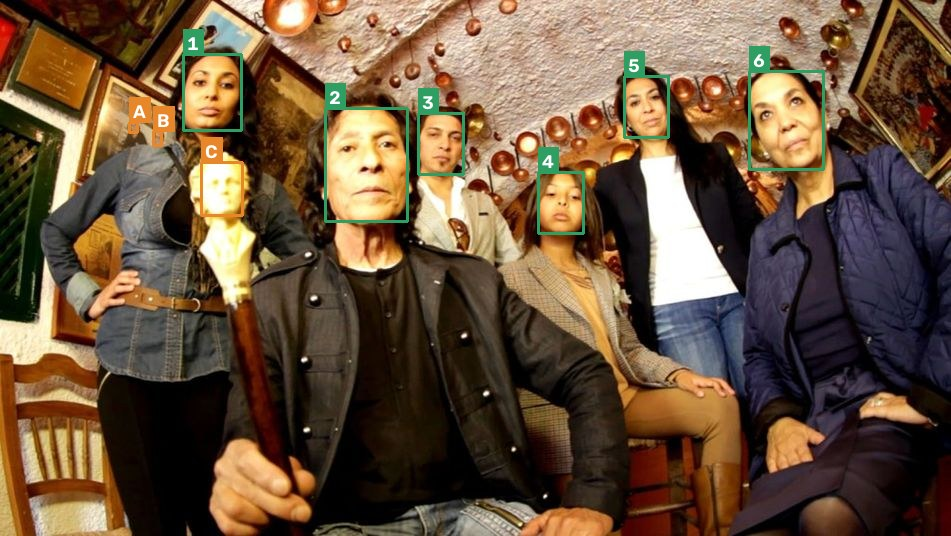
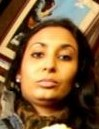
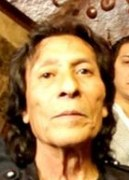
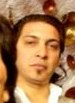
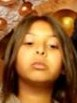
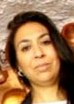
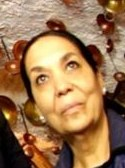
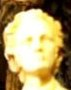

In [39]:
# ── Ejercicio 1 · Paso 4: montar el informe ─────────────────────────────────────
# Informe en HTML: foto con recuadros numerados, resumen del grupo, la escena
# y una ficha por persona. Se muestra aquí y se guarda en S3 con un enlace temporal.
import io, base64, html
from IPython.display import HTML, display

foto = Image.open(file_ej1).convert('RGB')
W, H = foto.size
VERDE, NARANJA = '#2f9e62', '#e8862a'

def a_base64(img, calidad=88):
    buf = io.BytesIO()
    img.save(buf, format='JPEG', quality=calidad)
    return base64.b64encode(buf.getvalue()).decode()

def recorte(f, margen=0.35, lado=180):
    x1, y1, x2, y2 = caja(f['cara']['BoundingBox'])
    w, h = x2 - x1, y2 - y1
    rec = foto.crop((int(max(0, x1 - w * margen) * W), int(max(0, y1 - h * margen) * H),
                     int(min(1, x2 + w * margen) * W), int(min(1, y2 + h * margen) * H)))
    rec.thumbnail((lado, lado))
    return a_base64(rec)

# --- Foto con los recuadros (verde: persona; naranja: cara que no es de una persona) ---
anotada = cv2.cvtColor(np.array(foto), cv2.COLOR_RGB2BGR)
grosor, escala = max(2, W // 450), max(0.5, W / 1500)
for f in fichas:
    x1, y1, x2, y2 = caja(f['cara']['BoundingBox'])
    p1, p2 = (int(x1 * W), int(y1 * H)), (int(x2 * W), int(y2 * H))
    color = (98, 158, 47) if f['tipo'] == 'persona' else (42, 134, 232)   # en BGR
    cv2.rectangle(anotada, p1, p2, color, grosor)
    (tw, th), _ = cv2.getTextSize(f['id'], cv2.FONT_HERSHEY_SIMPLEX, escala, 2)
    y_etiqueta = max(th + 8, p1[1])
    cv2.rectangle(anotada, (p1[0], y_etiqueta - th - 8), (p1[0] + tw + 8, y_etiqueta), color, -1)
    cv2.putText(anotada, f['id'], (p1[0] + 4, y_etiqueta - 4), cv2.FONT_HERSHEY_SIMPLEX, escala, (255, 255, 255), 2)
foto_anotada = a_base64(Image.fromarray(cv2.cvtColor(anotada, cv2.COLOR_BGR2RGB)))

# --- Piezas pequeñas del informe ---
def chip(texto, color='#eef1f5', tinta='#374151'):
    return f'<span class="chip" style="background:{color};color:{tinta}">{texto}</span>'

def chips_persona(f):
    c = f['cara']
    nombres = {'Smile': 'Sonríe', 'Eyeglasses': 'Gafas', 'Sunglasses': 'Gafas de sol', 'Beard': 'Barba',
               'Mustache': 'Bigote', 'MouthOpen': 'Boca abierta', 'FaceOccluded': 'Cara tapada'}
    salida = [chip(f"{n} · {c[a]['Confidence']:.0f} %") for a, n in nombres.items() if c[a]['Value']]
    if not c['EyesOpen']['Value']:
        salida.append(chip(f"Ojos cerrados · {c['EyesOpen']['Confidence']:.0f} %"))
    salida += [chip((PRENDAS.get(p['Nombre']) or ACCESORIOS[p['Nombre']]).split(' ', 1)[1].capitalize(),
                    '#e8f3ec', '#1f6b43') for p in f['ropa']]
    apariencia = 'Femenina' if c['Gender']['Value'] == 'Female' else 'Masculina'
    salida.append(chip(f"Apariencia {apariencia.lower()} · {c['Gender']['Confidence']:.0f} %"))
    return ''.join(dict.fromkeys(salida))

def barras_emociones(f):
    filas = ''
    for e in sorted(f['cara']['Emotions'], key=lambda e: -e['Confidence'])[:3]:
        if e['Confidence'] < 1:
            break
        filas += (f'<div class="emo"><span>{EMOCIONES[e["Type"]][1]}</span><b><i style="width:{e["Confidence"]:.0f}%">'
                  f'</i></b><span>{e["Confidence"]:.0f} %</span></div>')
    return filas

def lectura(f):
    """¿Nos podemos fiar de lo que dice el modelo de esta cara?"""
    c, dudas = f['cara'], []
    if c['FaceOccluded']['Value']:
        dudas.append('cara tapada')
    if abs(c['Pose']['Yaw']) > 35 or abs(c['Pose']['Pitch']) > 30:
        dudas.append('cabeza muy girada')
    if c['Quality']['Sharpness'] < 0.5 * nitidez_tipica:
        dudas.append('poco nítida')
    if c['Confidence'] < 95:
        dudas.append('cara poco clara')
    if not dudas:
        return '<span class="lectura" style="color:#2f9e62">● Lectura fiable</span>'
    color = '#d4a017' if len(dudas) == 1 else '#d0453a'
    return f'<span class="lectura" style="color:{color}">● Lectura con dudas: {", ".join(dudas)}</span>'

def etiquetas_escena(maximo=8, minimo=60):
    """Lo más seguro que ve Rekognition en la escena, sin repetir categorías generales."""
    excluir = {'Person Description', 'Apparel and Accessories', 'Expressions and Emotions',
               'Colors and Visual Composition'}
    vistas, padres = [], set()
    for l in sorted(etiquetas, key=lambda l: (-round(l['Confidence']), -len(l.get('Parents', [])))):
        cats = {c['Name'] for c in l.get('Categories', [])}
        if l['Name'] in ESCENA and l['Name'] not in padres and not cats & excluir and l['Confidence'] >= minimo:
            vistas.append(l)
            padres.update(p['Name'] for p in l.get('Parents', []))
        if len(vistas) == maximo:
            break
    return vistas

propiedades = resp_etiquetas.get('ImageProperties', {})
paleta = propiedades.get('DominantColors', [])[:6]
tonos = Counter()
for color in propiedades.get('DominantColors', []):
    tonos[color['SimplifiedColor']] += color['PixelPercent']
tonos_txt = lista([COLORES.get(t, t) for t, _ in tonos.most_common(3)]) if tonos else ''
calidad = propiedades.get('Quality', {})

# --- Montaje ---
if personas:
    emo_comun = EMOCIONES[Counter(emocion(f)['Type'] for f in personas).most_common(1)[0][0]][1]
    media_edad = f"{sum(edad_media(f) for f in personas) / n_personas:.0f}"
else:
    emo_comun, media_edad = '-', '-'
tiles = [(n_personas, 'personas'), (len(caras), 'caras detectadas'),
         (media_edad, 'años de media (aparente)'), (emo_comun, 'gesto más repetido')]

fichas_html = ''
for i, f in enumerate(personas):
    fichas_html += f'''
    <div class="ficha">
      <div class="foto-cara"><img src="data:image/jpeg;base64,{recorte(f)}"><span class="num">{f['id']}</span></div>
      <div class="cuerpo">
        <div class="cab"><b>Persona {f['id']}</b>{lectura(f)}</div>
        <p>{narrar(f, i)}</p>
        <div class="chips">{chips_persona(f)}</div>
        <div class="emos">{barras_emociones(f)}</div>
      </div>
    </div>'''

otras_html = ''.join(f'''
    <div class="ficha otra">
      <div class="foto-cara"><img src="data:image/jpeg;base64,{recorte(f, lado=120)}"><span class="num">{f['id']}</span></div>
      <div class="cuerpo"><div class="cab"><b>Cara {f['id']}</b></div><p>{narrar_otra(f)}</p></div>
    </div>''' for f in otras_caras)

escena_html = ''.join(chip(f"{ESCENA[l['Name']]} · {l['Confidence']:.0f} %") for l in etiquetas_escena())
paleta_html = ''.join(f'<div class="color"><i style="background:{c["HexCode"]}"></i>{c["PixelPercent"]:.0f} %</div>'
                      for c in paleta)
calidad_html = ' · '.join(f"{n} {calidad[k]:.0f}/100" for k, n in
                          [('Sharpness', 'nitidez'), ('Brightness', 'brillo'), ('Contrast', 'contraste')] if k in calidad)

informe = f'''
<style>
  .inf {{font-family: -apple-system, 'Segoe UI', Roboto, sans-serif; color:#1f2328; background:#f4f5f7;
         max-width:860px; padding:26px; border-radius:18px; line-height:1.5}}
  .inf h1 {{font-size:26px; margin:0; color:#1f2328}} .inf h2 {{font-size:17px; margin:28px 0 10px; color:#1f2328}}
  .inf .sub {{color:#6b7280; font-size:13px; margin-bottom:18px}}
  .inf .tiles {{display:grid; grid-template-columns:repeat(4,1fr); gap:10px; margin-bottom:16px}}
  .inf .tile {{background:#fff; border-radius:12px; padding:12px 14px; box-shadow:0 1px 3px #0001}}
  .inf .tile b {{display:block; font-size:24px}} .inf .tile span {{color:#6b7280; font-size:12px}}
  .inf .foto {{width:100%; border-radius:12px; display:block}}
  .inf .leyenda {{font-size:12px; color:#6b7280; margin:6px 0 14px}}
  .inf .punto {{display:inline-block; width:10px; height:10px; border-radius:3px; margin:0 4px 0 10px}}
  .inf .resumen {{background:#fff; border-radius:12px; padding:14px 16px; font-size:15px; margin:0}}
  .inf .escena {{background:#fff; border-radius:12px; padding:14px 16px; font-size:13px; color:#4b5563}}
  .inf .escena div {{margin:4px 0}}
  .inf .chip {{display:inline-block; border-radius:20px; padding:2px 10px; font-size:12px; margin:3px 4px 0 0}}
  .inf .paleta {{display:flex; gap:10px; margin-top:6px}}
  .inf .color {{font-size:11px; color:#6b7280; text-align:center}}
  .inf .color i {{display:block; width:38px; height:24px; border-radius:6px; border:1px solid #0001}}
  .inf .ficha {{display:flex; gap:16px; background:#fff; border-radius:14px; padding:14px; margin:10px 0;
               box-shadow:0 1px 3px #0001; border-left:5px solid {VERDE}}}
  .inf .ficha.otra {{border-left-color:{NARANJA}; background:#fbfaf8}}
  .inf .foto-cara {{position:relative; flex:none}}
  .inf .foto-cara img {{width:104px; height:104px; object-fit:cover; border-radius:10px}}
  .inf .otra .foto-cara img {{width:72px; height:72px}}
  .inf .num {{position:absolute; top:-7px; left:-7px; background:{VERDE}; color:#fff; font-weight:bold;
             font-size:13px; border-radius:50%; width:24px; height:24px; text-align:center; line-height:24px}}
  .inf .otra .num {{background:{NARANJA}}}
  .inf .cab {{display:flex; justify-content:space-between; gap:10px; font-size:16px}}
  .inf .lectura {{font-size:12px; font-weight:normal}}
  .inf .cuerpo p {{margin:4px 0 6px; font-size:14px}}
  .inf .nota {{display:block; color:#8a6d1e; font-size:12px; margin-top:4px}}
  .inf .emos {{margin-top:8px; max-width:330px}}
  .inf .emo {{display:grid; grid-template-columns:78px 1fr 40px; align-items:center; gap:8px;
             font-size:12px; color:#4b5563}}
  .inf .emo b {{background:#eef1f5; border-radius:4px; height:7px; overflow:hidden}}
  .inf .emo i {{display:block; height:7px; background:#7c8db5}}
  .inf .pie {{color:#9ca3af; font-size:11px; margin-top:22px}}
</style>
<div class="inf">
  <h1>Informe de personas</h1>
  <div class="sub">{html.escape(file_ej1)} · análisis con Amazon Rekognition (detect_faces + detect_labels)</div>
  <div class="tiles">{''.join(f'<div class="tile"><b>{v}</b><span>{t}</span></div>' for v, t in tiles)}</div>
  <img class="foto" src="data:image/jpeg;base64,{foto_anotada}">
  <div class="leyenda"><span class="punto" style="background:{VERDE};margin-left:0"></span>persona de la escena
    <span class="punto" style="background:{NARANJA}"></span>cara que no es de una persona</div>
  <p class="resumen">{resumen_grupo()}</p>
  <h2>La escena</h2>
  <div class="escena">
    <div><b>Lo que más claro ve Rekognition:</b> {escena_html or '-'}</div>
    <div><b>Colores:</b> predominan los tonos {tonos_txt or '-'}.
      <div class="paleta">{paleta_html}</div></div>
    <div><b>Calidad de la foto:</b> {calidad_html or '-'}</div>
  </div>
  <h2>Las personas, una a una</h2>
  {fichas_html or '<p>No hay personas en la escena.</p>'}
  {'<h2>Otras caras que ha encontrado Rekognition</h2>' + otras_html if otras_html else ''}
  <div class="pie">Edad, apariencia y emociones son estimaciones del modelo a partir de la imagen, no datos
    reales de las personas. Las etiquetas de la escena son automáticas y pueden contener errores.</div>
</div>'''

# --- Guardar: en local y en S3, con un enlace temporal para abrirlo en el navegador ---
pagina = f'<!DOCTYPE html><html lang="es"><head><meta charset="utf-8"><title>Informe · {html.escape(file_ej1)}</title></head><body style="margin:0;padding:20px;background:#e9ebef">{informe}</body></html>'
with open('informe_ej1.html', 'w', encoding='utf-8') as fichero:
    fichero.write(pagina)
try:
    clave_informe = 'informes/informe_ej1.html'
    s3.Object(aws_bucket, clave_informe).put(Body=pagina.encode('utf-8'), ContentType='text/html; charset=utf-8')
    url_informe = s3.meta.client.generate_presigned_url('get_object', ExpiresIn=3600,
                                                        Params={'Bucket': aws_bucket, 'Key': clave_informe})
    # El enlace lleva dentro las credenciales temporales del laboratorio: no se muestra en la salida
    enlace = (f'<p style="font-family:sans-serif;font-size:13px">💾 Guardado en S3 como <code>{clave_informe}</code>. '
              'Para abrirlo en el navegador, ejecuta <code>print(url_informe)</code> (enlace válido 1 hora).</p>')
except Exception as e:
    enlace = f'<p style="font-family:sans-serif;font-size:13px">No se ha podido guardar en S3: {html.escape(str(e))}</p>'

display(HTML(informe + enlace))


Rekognition ha encontrado 9 caras


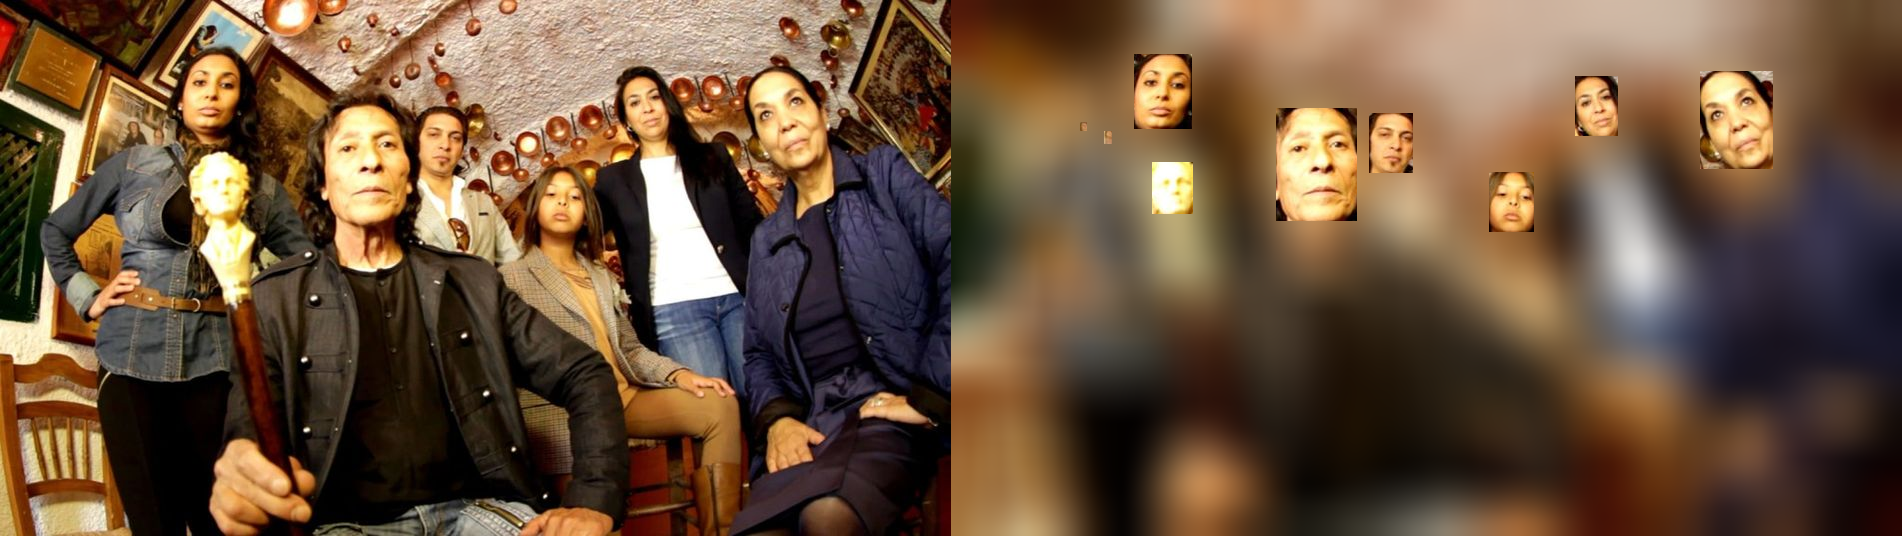

In [37]:
# ── Ejercicio 2: desenfocar toda la foto menos las caras ─────────────────────────
file_ej2 = 'caras_ej1.jpg'

# 1. Detectar las caras con Rekognition
s3.Object(aws_bucket, file_ej2).upload_file(file_ej2)
resp_ej2 = rekognition.detect_faces(Image={'S3Object': {'Bucket': aws_bucket, 'Name': file_ej2}})
print(f"Rekognition ha encontrado {len(resp_ej2['FaceDetails'])} caras")

# 2. Desenfocar la imagen entera
original = cv2.imread(file_ej2)              # OpenCV la lee ya en BGR, como espera cv2_imshow
alto, ancho = original.shape[:2]
resultado = cv2.GaussianBlur(original, (83, 83), 30)

# 3. Pegar encima cada cara de la imagen original, que está nítida
for cara in resp_ej2['FaceDetails']:
    box = cara['BoundingBox']
    x = max(0, int(ancho * box['Left']))     # max(0, ...) por si la cara se sale por el borde
    y = max(0, int(alto * box['Top']))
    w = int(ancho * box['Width'])
    h = int(alto * box['Height'])
    resultado[y:y+h, x:x+w] = original[y:y+h, x:x+w]

cv2.imwrite('faces_focus.jpg', resultado)
cv2_imshow(np.hstack([original, resultado]))   # antes | después


4 caras en una cuadrícula de 2x2


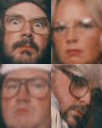

9 caras en una cuadrícula de 3x3


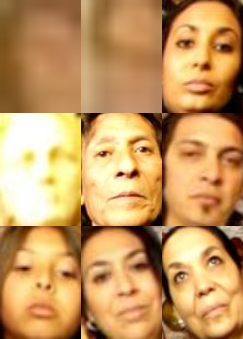

9 caras en una cuadrícula de 2x5


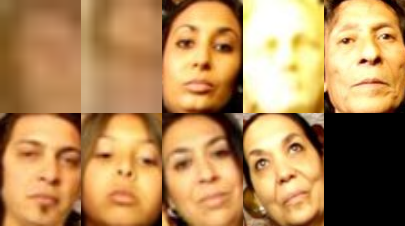

In [38]:
# ── Ejercicio 3: collage con las caras detectadas ───────────────────────────────
import math

def recortar_caras(fichero):
    """Detecta las caras con Rekognition y devuelve el recorte de cada una (de izquierda a derecha)."""
    s3.Object(aws_bucket, fichero).upload_file(fichero)
    resp = rekognition.detect_faces(Image={'S3Object': {'Bucket': aws_bucket, 'Name': fichero}})
    img = cv2.imread(fichero)
    alto, ancho = img.shape[:2]
    recortes = []
    for cara in sorted(resp['FaceDetails'], key=lambda c: c['BoundingBox']['Left']):
        box = cara['BoundingBox']
        x, y = max(0, int(ancho * box['Left'])), max(0, int(alto * box['Top']))
        w, h = int(ancho * box['Width']), int(alto * box['Height'])
        recortes.append(img[y:y+h, x:x+w])
    return recortes

def collage(recortes, filas=None, columnas=None):
    """Junta los recortes en una cuadrícula.
    Sin filas ni columnas, usa el cuadrado más pequeño en el que caben todos (5 caras → 3x3)."""
    n = len(recortes)
    if n == 0:
        print('No hay caras para hacer el collage')
        return None
    if columnas is None:
        columnas = math.ceil(math.sqrt(n)) if filas is None else math.ceil(n / filas)
    if filas is None:
        filas = math.ceil(n / columnas)
    print(f"{n} caras en una cuadrícula de {filas}x{columnas}")
    if filas * columnas < n:
        print(f"Aviso: solo caben {filas * columnas} caras, el resto se queda fuera")

    # Todas las caras al tamaño de la más grande (alguna se deformará un poco)
    w = max(r.shape[1] for r in recortes)
    h = max(r.shape[0] for r in recortes)
    caras = [cv2.resize(r, (w, h)) for r in recortes]

    # Rellenar las casillas que sobran con negro y montar fila a fila
    caras += [np.zeros((h, w, 3), dtype=np.uint8)] * (filas * columnas - n)
    filas_img = [np.hstack(caras[f * columnas:(f + 1) * columnas]) for f in range(filas)]
    return np.vstack(filas_img)

# Collage automático con dos fotos con distinto número de caras
recortes_por_foto = {}
for fichero in ['caras.jpg', 'caras_ej1.jpg']:
    recortes_por_foto[fichero] = recortar_caras(fichero)
    resultado = collage(recortes_por_foto[fichero])
    cv2.imwrite('collage_' + fichero, resultado)
    cv2_imshow(resultado)

# Ampliación: elegir a mano las filas y las columnas
a_medida = collage(recortes_por_foto['caras_ej1.jpg'], filas=2, columnas=5)
cv2.imwrite('collage_2x5.jpg', a_medida)
cv2_imshow(a_medida)
